
    **Trabalho Final - Análise de Antenas - 2026/2**

André Fabiano Silva Rios - 2026681087


Bibliotecas:

In [76]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import jv

pi = np.pi

PARTE 1

\begin{equation}
    E_{\theta}(\theta,\phi) \propto cos(\theta) cos(\phi)\int_0^{2\pi} \int_0^a\rho'\ ^2 e^{jk\rho'sen(\theta)cos(\phi-\phi')}d\rho'd\phi'
\end{equation}

\begin{equation}
    E_{\phi}(\theta,\phi) \propto -sen(\phi)\int_0^{2\pi} \int_0^a\rho' \ ^2 e^{jk\rho'sen(\theta)cos(\phi-\phi')}d\rho'd\phi'
\end{equation}

c:\Users\User\AppData\Local\Programs\Python\Python310\lib\site-packages\matplotlib\cbook.py:1719: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
c:\Users\User\AppData\Local\Programs\Python\Python310\lib\site-packages\matplotlib\cbook.py:1355: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


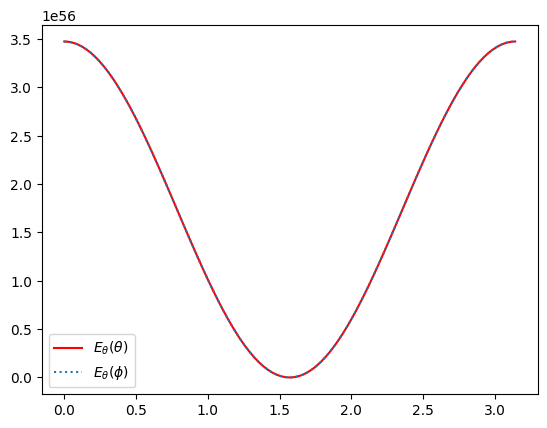

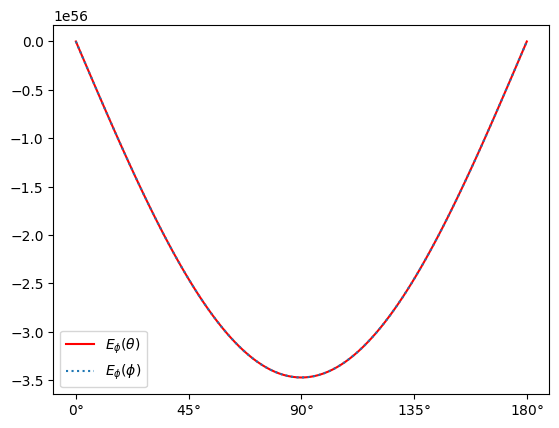

In [82]:
num = 102  ### Número de pontos
if num % 2 == 0: num += 1

theta = np.linspace(0,pi,num)
phi = np.linspace(0,pi,num)

a = 1
b = 0

lamb = 100

k = (2*pi)/lamb

f = lambda rho_s,phi_s : rho_s ** 2 * np.exp(1j*k*rho_s*np.sin(theta)*np.cos(phi-phi_s))

### Intervalo de análise
x2 = a
x1 = 0

y2 = 2*pi
y1 = 0

pontos = np.linspace(x1,x2,num)
pontos2 = np.linspace(y1,y2,num)

h = (x2-x1)/(num-1)
I = f(x1,pontos2) + f(x2,pontos2)

for i in range(1,num-1):
    if i % 2 == 0: I += 2*f(pontos[i],pontos2)
    else: I += 4*f(pontos[i],pontos2)

I = (h/3) * I

for i in range(1,num-1):
    if i % 2 == 0: I += 2*I[i]
    else: I += 4*I[i]

I = (h/3) * I

E_theta = np.zeros((len(theta),len(phi)),dtype=complex)
E_theta = np.cos(theta)*np.cos(phi)*I

E_phi = np.zeros((len(theta),len(phi)),dtype=complex)
E_phi = -np.sin(phi)*I

plt.figure()
plt.plot(theta,E_theta,label=r'$E_{\theta}(\theta)$',color='red')
plt.plot(phi,E_theta,ls=':',label=r'$E_{\theta}(\phi)$')
plt.legend()
plt.show()

plt.figure()
plt.plot(theta,E_phi,label=r'$E_{\phi}(\theta)$',color='red')
plt.plot(phi,E_phi,ls=':',label=r'$E_{\phi}(\phi)$')
plt.xticks([ 0, np.pi/4, np.pi/2,3*np.pi/4, np.pi],
           [r"$0°$", r"$45°$", r"$90°$",r"$135°$",r"$180°$"])
plt.legend()
plt.show()

Parte 2

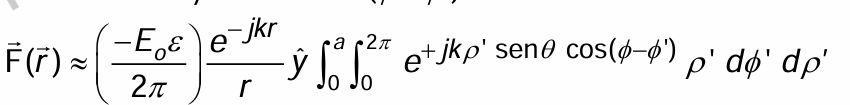

INTEGRAR DE b ATÉ a

y_hat = cos(theta)sen(phi) theta_hat + cos(phi) phi_hat

E(theta,phi) =

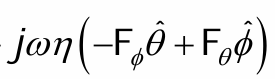

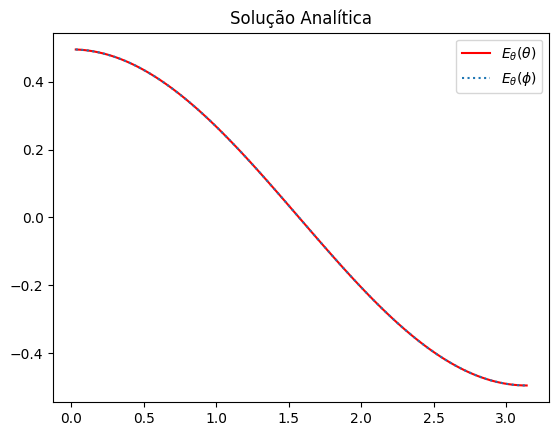

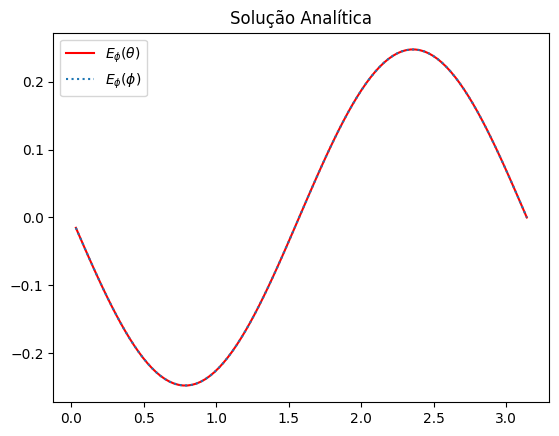

In [78]:
b = a/10

I = a*(jv(1,k*a*np.sin(theta[1:])))/(k*np.sin(theta[1:])) - b*(jv(1,k*b*np.sin(theta[1:])))/(k*np.sin(theta[1:]))


E_theta = np.cos(phi[1:])*I
E_phi = -np.cos(theta[1:])*np.sin(phi[1:])*I

plt.figure()
plt.title('Solução Analítica')
plt.plot(theta[1:],E_theta,label=r'$E_{\theta}(\theta)$',color='red')
plt.plot(phi[1:],E_theta,ls=':',label=r'$E_{\theta}(\phi)$')
plt.legend()
plt.show()

plt.figure()
plt.title('Solução Analítica')
plt.plot(theta[1:],E_phi,label=r'$E_{\phi}(\theta)$',color='red')
plt.plot(phi[1:],E_phi,ls=':',label=r'$E_{\phi}(\phi)$')
plt.legend()
plt.show()

Parte 3